# Benchmark results and graph explorer

Run this notebook to explore the archived policy comparisons. It reads completed JSON exports from `research/results/raw/` and the paired statistics table.

The current archive covers 50-task workloads. Network profiles are simulated RTTs and workers share one physical host, so interpret the charts as local prototype results.

In [2]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

# Locate research/ whether Jupyter starts in the repository root or research/.
candidates = [Path.cwd(), Path.cwd() / 'research', Path.cwd().parent]
RESEARCH = next((p.resolve() for p in candidates if (p / 'results' / 'raw').is_dir()), None)
if RESEARCH is None:
    raise FileNotFoundError('Could not find research/results/raw; open this notebook from the repository or research folder.')
RESULTS = RESEARCH / 'results'
raw_files = sorted((RESULTS / 'raw').glob('*.json'))
if not raw_files:
    raise FileNotFoundError(f'No JSON exports found in {RESULTS / "raw"}')
print(f'Research folder: {RESEARCH}')
print(f'Raw experiment exports: {len(raw_files)}')

Research folder: /home/uzueer/Edge/research
Raw experiment exports: 12


In [3]:
records = []
for path in raw_files:
    payload = json.loads(path.read_text(encoding='utf-8'))
    experiment = payload.get('experiment', {})
    configuration = experiment.get('configuration', {})
    scenario = configuration.get('scenario') or {}
    for result in payload.get('results', []):
        metrics = result.get('metrics') or {}
        if metrics.get('resultType') != 'task':
            continue
        records.append({
            'experiment_id': experiment.get('id'),
            'algorithm': result.get('algorithm'),
            'status': metrics.get('status', 'unknown'),
            'response_ms': metrics.get('actualResponseMs'),
            'repetition': result.get('repetition'),
            'worker': result.get('nodeId') or 'unassigned',
            'network_profile': scenario.get('networkProfile', 'unknown'),
            'capacity_profile': scenario.get('capacityProfile', 'unknown'),
            'task_count': scenario.get('taskCount', configuration.get('taskCount')),
        })
tasks = pd.DataFrame(records)
if tasks.empty:
    raise ValueError('The exports contain no task-level records.')
successful = tasks[(tasks['status'] == 'succeeded') & tasks['response_ms'].notna()].copy()
summary = tasks.groupby('algorithm').agg(
    task_records=('status', 'size'),
    succeeded=('status', lambda s: (s == 'succeeded').sum()),
    success_rate=('status', lambda s: (s == 'succeeded').mean()),
).join(successful.groupby('algorithm')['response_ms'].agg(['mean', 'median']))
summary

,task_records,succeeded,success_rate,mean,median
algorithm,,,,,
edge-only,18000,18000,1.0,38.582004,28.196635
latency-aware,18000,18000,1.0,40.543448,33.128713
round-robin,18000,18000,1.0,59.854375,53.175772


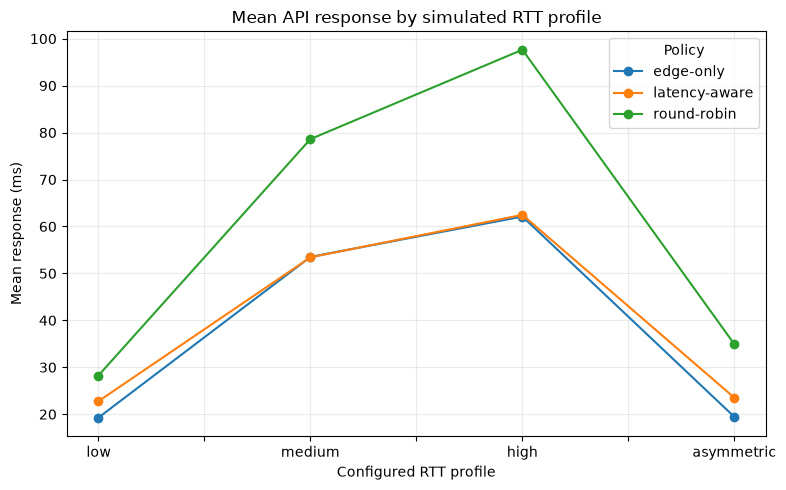

In [4]:
plt.rcParams.update({'figure.figsize': (8, 5), 'font.size': 10})
rtt_summary = successful.groupby(['network_profile', 'algorithm'], as_index=False)['response_ms'].mean()
rtt_order = ['low', 'medium', 'high', 'asymmetric']
rtt_pivot = rtt_summary.pivot(index='network_profile', columns='algorithm', values='response_ms').reindex(rtt_order)
ax = rtt_pivot.plot(marker='o')
ax.set(title='Mean API response by simulated RTT profile', xlabel='Configured RTT profile', ylabel='Mean response (ms)')
ax.grid(alpha=.25)
ax.legend(title='Policy')
plt.tight_layout()
plt.savefig(RESULTS / 'graphs' / 'notebook_response_by_rtt.png', dpi=250, bbox_inches='tight')
plt.show()

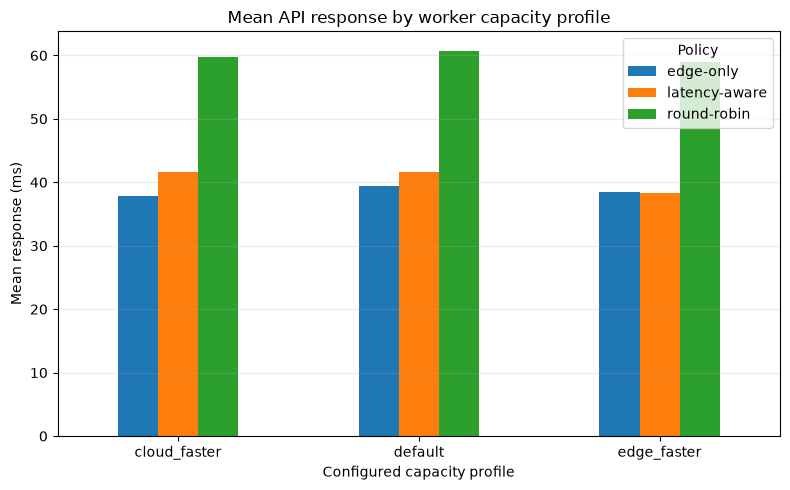

In [5]:
capacity_summary = successful.groupby(['capacity_profile', 'algorithm'], as_index=False)['response_ms'].mean()
capacity_pivot = capacity_summary.pivot(index='capacity_profile', columns='algorithm', values='response_ms')
ax = capacity_pivot.plot(kind='bar')
ax.set(title='Mean API response by worker capacity profile', xlabel='Configured capacity profile', ylabel='Mean response (ms)')
ax.grid(axis='y', alpha=.25)
ax.legend(title='Policy')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS / 'graphs' / 'notebook_response_by_capacity.png', dpi=250, bbox_inches='tight')
plt.show()

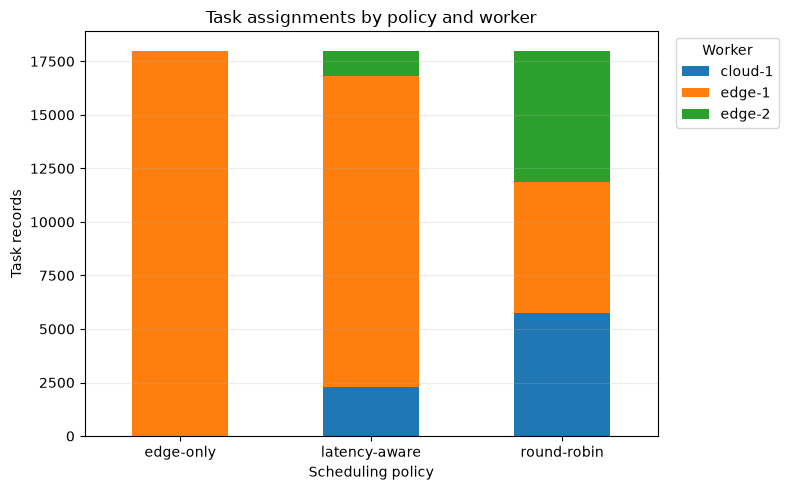

In [6]:
worker_counts = tasks.groupby(['algorithm', 'worker']).size().unstack(fill_value=0)
ax = worker_counts.plot(kind='bar', stacked=True)
ax.set(title='Task assignments by policy and worker', xlabel='Scheduling policy', ylabel='Task records')
ax.grid(axis='y', alpha=.25)
ax.legend(title='Worker', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS / 'graphs' / 'notebook_worker_distribution.png', dpi=250, bbox_inches='tight')
plt.show()

,experimentId,taskCount,networkProfile,capacityProfile,baseline,independentRepetitionCount,meanBaselineMinusLatencyAwareMs,pairedCohensDz,pValueWilcoxon,pValueHolmAcrossMatrix,condition,baselineMinusLatencyAwareMs
15,97c57148-42d6-422b-8b9f-d3351838dd33,50,asymmetric,cloud_faster,edge-only,30,-6.813527,-3.484584,1.862645e-09,4.470348e-08,asymmetric / cloud_faster,-6.813527
9,453feb19-d6d3-4e22-9861-9fc6713ab166,50,asymmetric,default,edge-only,30,-5.914891,-3.447112,1.862645e-09,4.470348e-08,asymmetric / default,-5.914891
3,233c6845-e0fa-43d2-bce3-8a289823aa03,50,asymmetric,edge_faster,edge-only,30,0.492817,0.502596,3.744433e-03,3.127640e-02,asymmetric / edge_faster,0.492817
23,c07e2111-507d-424b-8585-2ec26cb23c3f,50,high,cloud_faster,edge-only,30,-0.594601,-0.095127,2.129329e-01,1.000000e+00,high / cloud_faster,-0.594601
5,304746e3-41ec-40bb-b31d-3378fae4e7e1,50,high,default,edge-only,30,0.665486,0.122623,7.765688e-01,1.000000e+00,high / default,0.665486
17,9fdeecbd-91ce-44eb-9aa6-6645e923c0e2,50,high,edge_faster,edge-only,30,-1.156716,-0.389341,1.094321e-01,7.660244e-01,high / edge_faster,-1.156716
1,21fddb6f-8800-48b3-94d6-cecbe7079bfc,50,low,cloud_faster,edge-only,30,-7.248252,-2.033016,9.983778e-07,9.983778e-06,low / cloud_faster,-7.248252
19,a9093359-6d04-4fe9-8be2-08a7bced2d6a,50,low,default,edge-only,30,-3.164021,-1.327658,1.862645e-09,4.470348e-08,low / default,-3.164021
21,ac0c4869-c58f-414e-a192-b8ce74adf301,50,low,edge_faster,edge-only,30,-0.072994,-0.046967,9.838336e-01,1.000000e+00,low / edge_faster,-0.072994
7,3aaa1023-c609-4f8a-9391-eeede3a7ab2e,50,medium,cloud_faster,edge-only,30,-0.137876,-0.014335,5.837571e-01,1.000000e+00,medium / cloud_faster,-0.137876


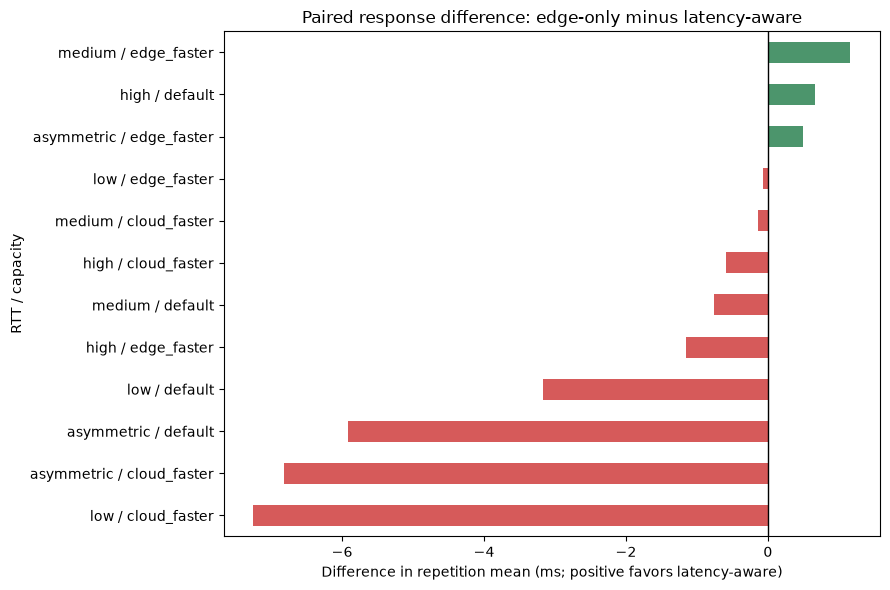

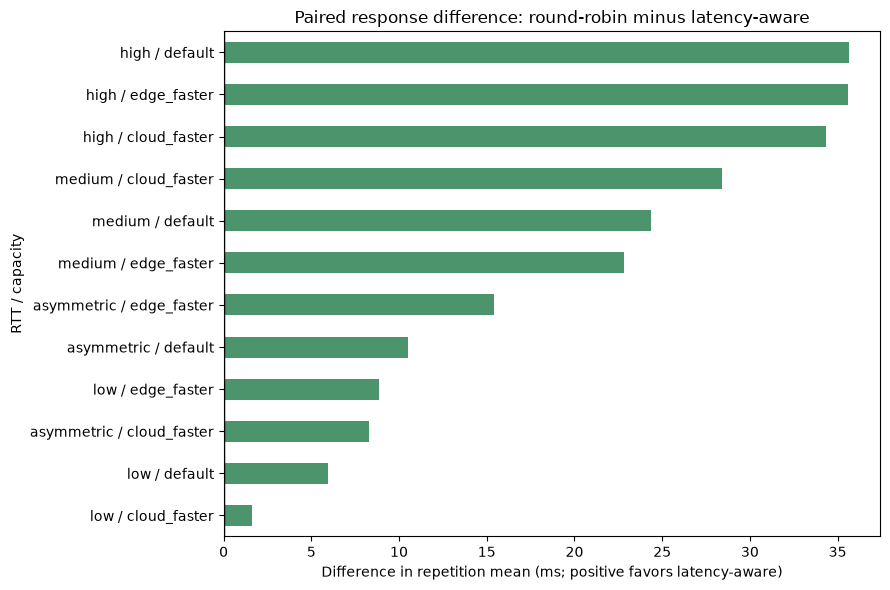

In [7]:
paired_path = RESULTS / 'graphs' / 'paired_matrix_comparisons.csv'
if paired_path.exists():
    paired = pd.read_csv(paired_path)
    paired['condition'] = paired['networkProfile'].astype(str) + ' / ' + paired['capacityProfile'].astype(str)
    paired['baselineMinusLatencyAwareMs'] = pd.to_numeric(paired['meanBaselineMinusLatencyAwareMs'], errors='coerce')
    paired['pValueHolmAcrossMatrix'] = pd.to_numeric(paired['pValueHolmAcrossMatrix'], errors='coerce')
    display(paired.sort_values(['baseline', 'networkProfile', 'capacityProfile']))
    for baseline, frame in paired.groupby('baseline'):
        frame = frame.sort_values('baselineMinusLatencyAwareMs')
        colors = ['#4c956c' if value > 0 else '#d65a5a' for value in frame['baselineMinusLatencyAwareMs']]
        ax = frame.plot.barh(x='condition', y='baselineMinusLatencyAwareMs', legend=False, color=colors, figsize=(9, 6))
        ax.axvline(0, color='black', linewidth=1)
        ax.set(title=f'Paired response difference: {baseline} minus latency-aware', xlabel='Difference in repetition mean (ms; positive favors latency-aware)', ylabel='RTT / capacity')
        plt.tight_layout()
        safe_name = baseline.replace('-', '_')
        plt.savefig(RESULTS / 'graphs' / f'notebook_paired_{safe_name}.png', dpi=250, bbox_inches='tight')
        plt.show()
else:
    print('Paired matrix table is missing. Run research/experiments/generate_graphs.py first.')